In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
from PIL import Image
import os

In [ ]:
print("Please upload these 3 coin images:")
print("1. 20.jpg")
print("2. File_2009phil10centobv_jpg - Wikimedia Commons.jpeg")
print("3. Philippine peso - Wikiwand.jpeg")
print()

uploaded = files.upload()

Please upload these 3 coin images:
1. 20.jpg
2. File_2009phil10centobv_jpg - Wikimedia Commons.jpeg
3. Philippine peso - Wikiwand.jpeg



Saving File_2009phil10centobv_jpg - Wikimedia Commons.jpeg to File_2009phil10centobv_jpg - Wikimedia Commons (2).jpeg
Saving Philippine peso - Wikiwand.jpeg to Philippine peso - Wikiwand (2).jpeg
Saving 20.jpg to 20 (2).jpg


In [ ]:
print("\nUploaded files:")

for filename in uploaded.keys():
    print("-", filename)


Uploaded files:
- File_2009phil10centobv_jpg - Wikimedia Commons (2).jpeg
- Philippine peso - Wikiwand (2).jpeg
- 20 (2).jpg


In [ ]:
coin20_file = "20.jpg"

coin010_file = "File_2009phil10centobv_jpg - Wikimedia Commons.jpeg"

coin1_file = "Philippine peso - Wikiwand.jpeg"

In [ ]:
required_files = [
    coin20_file,
    coin1_file,
    coin010_file
]

for filename in required_files:

    if not os.path.exists(filename):

        raise FileNotFoundError(
            f"File not found: {filename}\n"
            "Please upload the correct coin image."
        )


print("\nAll three coin images were found.")


All three coin images were found.


In [ ]:
coin20_bgr = cv2.imread(
    coin20_file,
    cv2.IMREAD_COLOR
)

coin1_bgr = cv2.imread(
    coin1_file,
    cv2.IMREAD_COLOR
)

coin010_bgr = cv2.imread(
    coin010_file,
    cv2.IMREAD_COLOR
)


if coin20_bgr is None:
    raise ValueError("Failed to load the ₱20 image.")

if coin1_bgr is None:
    raise ValueError("Failed to load the ₱1 image.")

if coin010_bgr is None:
    raise ValueError("Failed to load the ₱0.10 image.")

In [ ]:
coin20_rgb = cv2.cvtColor(
    coin20_bgr,
    cv2.COLOR_BGR2RGB
)

coin1_rgb = cv2.cvtColor(
    coin1_bgr,
    cv2.COLOR_BGR2RGB
)

coin010_rgb = cv2.cvtColor(
    coin010_bgr,
    cv2.COLOR_BGR2RGB
)

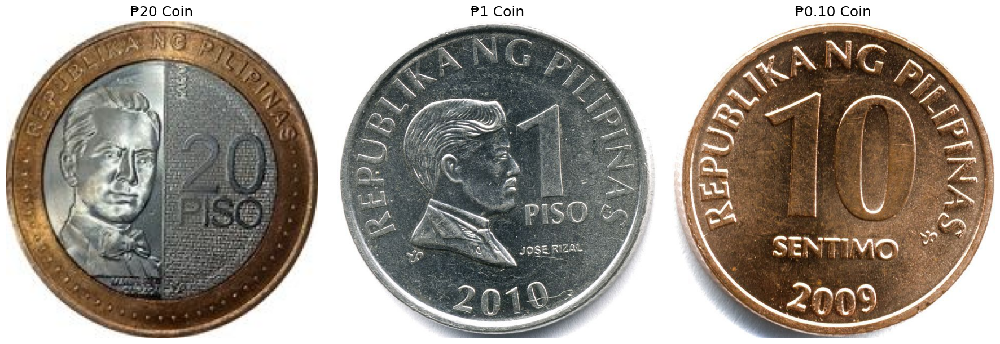

In [ ]:
plt.figure(figsize=(18, 6))


plt.subplot(1, 3, 1)
plt.imshow(coin20_rgb)
plt.title("₱20 Coin", fontsize=18)
plt.axis("off")


plt.subplot(1, 3, 2)
plt.imshow(coin1_rgb)
plt.title("₱1 Coin", fontsize=18)
plt.axis("off")


plt.subplot(1, 3, 3)
plt.imshow(coin010_rgb)
plt.title("₱0.10 Coin", fontsize=18)
plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
coin_width = 500
coin_height = 500

coin20_rgb = cv2.resize(
    coin20_rgb,
    (coin_width, coin_height),
    interpolation=cv2.INTER_CUBIC
)

coin1_rgb = cv2.resize(
    coin1_rgb,
    (coin_width, coin_height),
    interpolation=cv2.INTER_CUBIC
)

coin010_rgb = cv2.resize(
    coin010_rgb,
    (coin_width, coin_height),
    interpolation=cv2.INTER_CUBIC
)

In [ ]:
combined_rgb = np.hstack(
    (
        coin20_rgb,
        coin1_rgb,
        coin010_rgb
    )
)

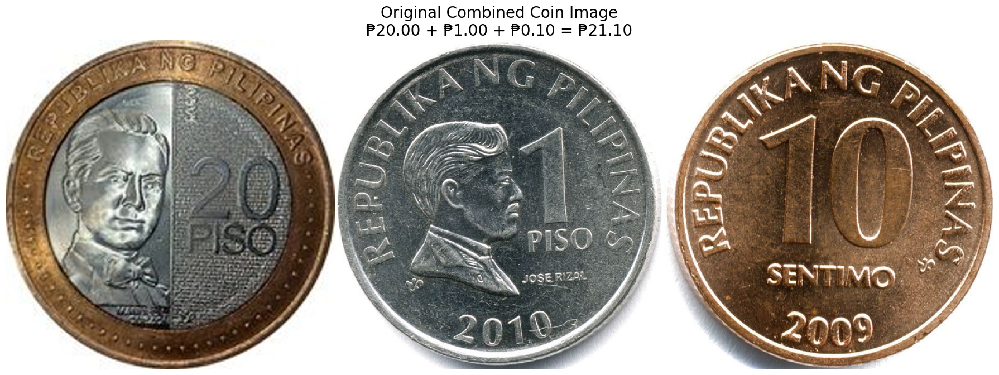

In [ ]:
plt.figure(figsize=(18, 7))

plt.imshow(combined_rgb)

plt.title(
    "Original Combined Coin Image\n"
    "₱20.00 + ₱1.00 + ₱0.10 = ₱21.10",
    fontsize=20
)

plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
combined_bgr = cv2.cvtColor(
    combined_rgb,
    cv2.COLOR_RGB2BGR
)

cv2.imwrite(
    "01_original_combined.png",
    combined_bgr
)


print("Original combined image saved.")

Original combined image saved.


In [ ]:
gray = cv2.cvtColor(
    combined_rgb,
    cv2.COLOR_RGB2GRAY
)

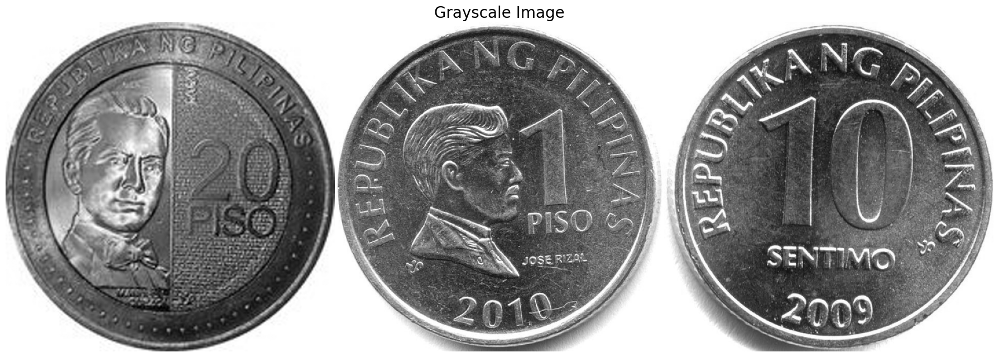

In [ ]:
plt.figure(figsize=(18, 7))

plt.imshow(
    gray,
    cmap="gray"
)

plt.title(
    "Grayscale Image",
    fontsize=20
)

plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
kernel_gaussian = np.array([
    [1,  4,  6,  4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1,  4,  6,  4, 1]
], dtype=np.float32) / 256

In [ ]:
blurred = cv2.filter2D(
    gray,
    -1,
    kernel_gaussian
)

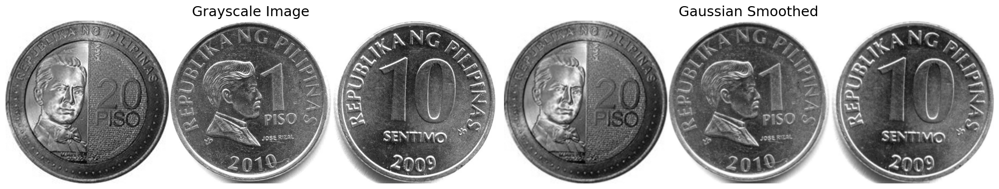

In [ ]:
plt.figure(figsize=(18, 7))


plt.subplot(1, 2, 1)

plt.imshow(
    gray,
    cmap="gray"
)

plt.title(
    "Grayscale Image",
    fontsize=18
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    blurred,
    cmap="gray"
)

plt.title(
    "Gaussian Smoothed",
    fontsize=18
)

plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
cv2.imwrite(
    "02_grayscale_filtered.png",
    blurred
)

True

In [ ]:
sharpening_kernel = np.array([
    [0, -1, 0],
    [-1, 7, -1],
    [0, -1, 0]
])

In [ ]:
sharpened = cv2.filter2D(
    blurred,
    -1,
    sharpening_kernel
)

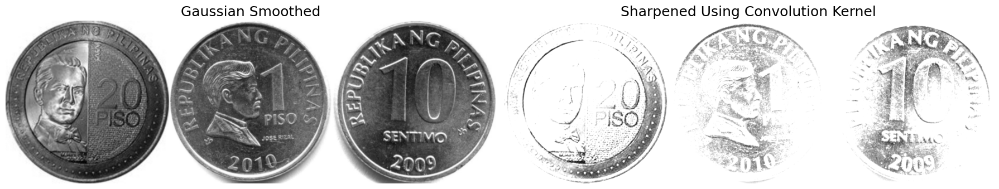

In [ ]:
plt.figure(figsize=(18, 7))


plt.subplot(1, 2, 1)

plt.imshow(
    blurred,
    cmap="gray"
)

plt.title(
    "Gaussian Smoothed",
    fontsize=18
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    sharpened,
    cmap="gray"
)

plt.title(
    "Sharpened Using Convolution Kernel",
    fontsize=18
)

plt.axis("off")


plt.tight_layout()
plt.show()


In [ ]:
cv2.imwrite(
    "03_convolution_sharpened.png",
    sharpened
)

True

In [ ]:
sobel_x = cv2.Sobel(
    sharpened,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

sobel_y = cv2.Sobel(
    sharpened,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)


sobel_x = cv2.convertScaleAbs(
    sobel_x
)

sobel_y = cv2.convertScaleAbs(
    sobel_y
)


sobel_combined = cv2.addWeighted(
    sobel_x,
    0.5,
    sobel_y,
    0.5,
    0
)

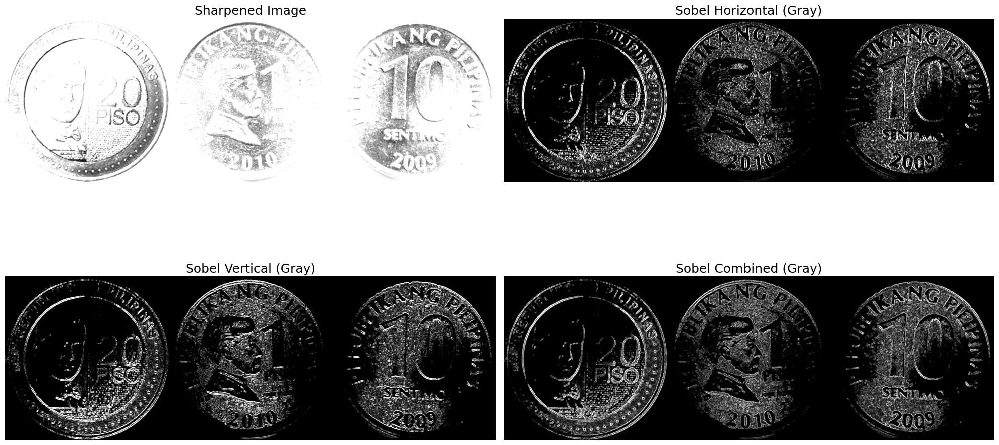

In [ ]:
plt.figure(figsize=(20, 12))


plt.subplot(2, 2, 1)

plt.imshow(
    sharpened,
    cmap="gray"
)

plt.title(
    "Sharpened Image",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 2)

plt.imshow(
    sobel_x,
    cmap="gray"
)

plt.title(
    "Sobel Horizontal (Gray)",
    fontsize=18
)

plt.axis("off")

plt.subplot(2, 2, 3)

plt.imshow(
    sobel_y,
    cmap="gray"
)

plt.title(
    "Sobel Vertical (Gray)",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 4)

plt.imshow(
    sobel_combined,
    cmap="gray"
)

plt.title(
    "Sobel Combined (Gray)",
    fontsize=18
)

plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
kernel_prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)


kernel_prewitt_y = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1]
], dtype=np.float32)


# Apply Prewitt

prewitt_x = cv2.filter2D(
    sharpened,
    -1,
    kernel_prewitt_x
)

prewitt_y = cv2.filter2D(
    sharpened,
    -1,
    kernel_prewitt_y
)

prewitt_combined = cv2.addWeighted(
    prewitt_x,
    0.5,
    prewitt_y,
    0.5,
    0
)

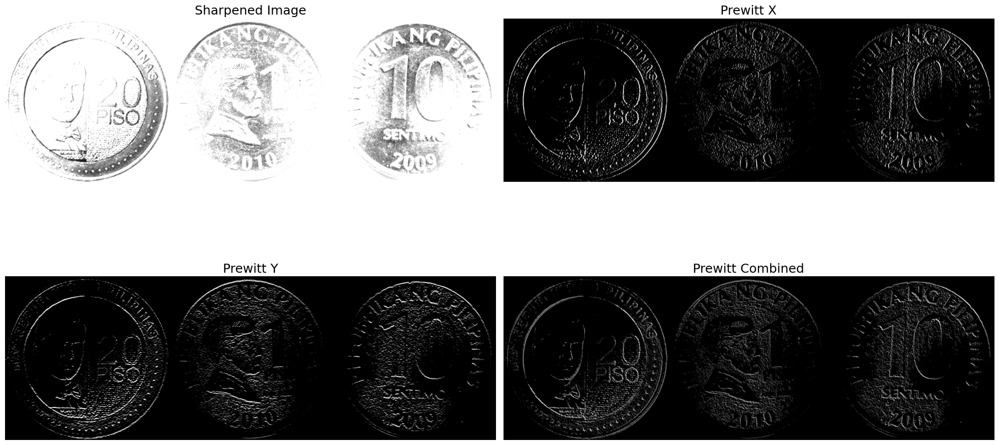

In [ ]:
plt.figure(figsize=(20, 12))


plt.subplot(2, 2, 1)

plt.imshow(
    sharpened,
    cmap="gray"
)

plt.title(
    "Sharpened Image",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 2)

plt.imshow(
    prewitt_x,
    cmap="gray"
)

plt.title(
    "Prewitt X",
    fontsize=18
)

plt.axis("off")

plt.subplot(2, 2, 3)

plt.imshow(
    prewitt_y,
    cmap="gray"
)

plt.title(
    "Prewitt Y",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 4)

plt.imshow(
    prewitt_combined,
    cmap="gray"
)

plt.title(
    "Prewitt Combined",
    fontsize=18
)

plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
canny_edges = cv2.Canny(
    blurred,
    threshold1=50,
    threshold2=150
)

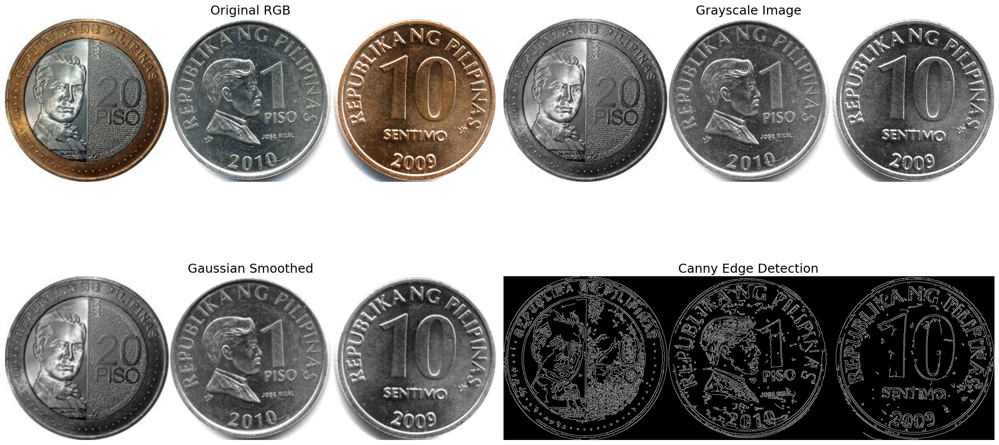

In [ ]:
plt.figure(figsize=(20, 12))


plt.subplot(2, 2, 1)

plt.imshow(
    combined_rgb
)

plt.title(
    "Original RGB",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 2)

plt.imshow(
    gray,
    cmap="gray"
)

plt.title(
    "Grayscale Image",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 3)

plt.imshow(
    blurred,
    cmap="gray"
)

plt.title(
    "Gaussian Smoothed",
    fontsize=18
)

plt.axis("off")


plt.subplot(2, 2, 4)

plt.imshow(
    canny_edges,
    cmap="gray"
)

plt.title(
    "Canny Edge Detection",
    fontsize=18
)

plt.axis("off")


plt.tight_layout()
plt.show()


In [ ]:
cv2.imwrite(
    "04_final_edge_detected.png",
    canny_edges
)

True

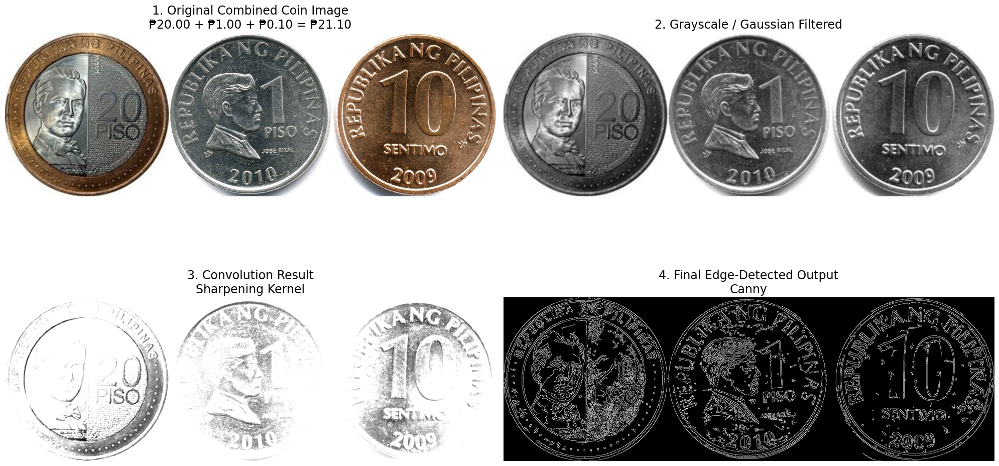

In [ ]:
plt.figure(figsize=(20, 12))


# 1. Original

plt.subplot(2, 2, 1)

plt.imshow(
    combined_rgb
)

plt.title(
    "1. Original Combined Coin Image\n"
    "₱20.00 + ₱1.00 + ₱0.10 = ₱21.10",
    fontsize=17
)

plt.axis("off")


# 2. Grayscale / Filtered

plt.subplot(2, 2, 2)

plt.imshow(
    blurred,
    cmap="gray"
)

plt.title(
    "2. Grayscale / Gaussian Filtered",
    fontsize=17
)

plt.axis("off")


# 3. Convolution

plt.subplot(2, 2, 3)

plt.imshow(
    sharpened,
    cmap="gray"
)

plt.title(
    "3. Convolution Result\n"
    "Sharpening Kernel",
    fontsize=17
)

plt.axis("off")


# 4. Edge detection

plt.subplot(2, 2, 4)

plt.imshow(
    canny_edges,
    cmap="gray"
)

plt.title(
    "4. Final Edge-Detected Output\n"
    "Canny",
    fontsize=17
)

plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
print()
print("=" * 65)
print("LABORATORY ACTIVITY 1: COIN DETECTION")
print("=" * 65)
print()
print("SELECTED COINS")
print("----------------")
print("₱20.00")
print("₱1.00")
print("₱0.10")
print()
print("TOTAL: ₱21.10")
print()
print("PROCESSING")
print("----------------")
print("1. Grayscale conversion")
print("2. Gaussian smoothing")
print("3. Sharpening convolution")
print("4. Sobel edge detection")
print("5. Prewitt edge detection")
print("6. Canny edge detection")
print()
print("OUTPUT FILES")
print("----------------")
print("01_original_combined.png")
print("02_grayscale_filtered.png")
print("03_convolution_sharpened.png")
print("04_final_edge_detected.png")
print()
print("Processing completed.")
print("=" * 65)


LABORATORY ACTIVITY 1: COIN DETECTION

SELECTED COINS
----------------
₱20.00
₱1.00
₱0.10

TOTAL: ₱21.10

PROCESSING
----------------
1. Grayscale conversion
2. Gaussian smoothing
3. Sharpening convolution
4. Sobel edge detection
5. Prewitt edge detection
6. Canny edge detection

OUTPUT FILES
----------------
01_original_combined.png
02_grayscale_filtered.png
03_convolution_sharpened.png
04_final_edge_detected.png

Processing completed.


Short Explanation

Kernel Used:
The images of the coins have been sharpened using a 3×3 sharpening kernel. The kernel made the outlines and the markings on the coins more prominent.

Convolution Process:
The images of the coins selected were first converted to grayscale and noise was removed from the images through filtering. The sharpening kernel was then convolved to highlight the details and the outlines of the coins.

Edge Detection Method:
The coins' edges were detected using canny edge detection. It showed clear boundaries of the circular coins and helped to separate the edges from the background.

How the results were enhanced:
Grayscale conversion and noise reduction were performed prior to convolution and edge detection to obtain a better result. The output was cleaned to reduce noise without obscuring the circular edges of the coins and to ensure that the coin markings were still visible, which enabled the three coins and the overall amount of ₱21.10 to be identified.